In [1]:
from Functions import *
from Rewiring_functions import *
import itertools

In [2]:
#read databases of interactions, distances among sites and land categories cover
filename1="./DATA/Clough/clough_data.csv"
filename2="./DATA/Clough/clough_pairwise_distance.csv"
filename3="./DATA/Clough/landscvars.csv"

In [3]:
df1 = pd.read_csv(
    filename1, sep=";", decimal=",",index_col=0)

In [4]:
df1[df1["Network_id"]=="TAG"]

,Study_id,Network_id,Sampling_method,Authors_habitat,EuPPollNet_habitat,Bioregion,Country,Locality,Latitude,Longitude,...,Pollinator_original_name,Pollinator_accepted_name,Pollinator_rank,Pollinator_order,Pollinator_family,Pollinator_genus,Pollinator_unsure_id,Pollinator_uncertainty_type,Flower_data,Flower_data_merger
2168,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Saltella sphondylii (Schrank,1803)",Saltella sphondylii,SPECIES,Diptera,Sepsidae,Saltella,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2169,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Saltella sphondylii (Schrank,1803)",Saltella sphondylii,SPECIES,Diptera,Sepsidae,Saltella,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2170,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Acupalpus exiguus Dejean,1829",Acupalpus exiguus,SPECIES,Coleoptera,Carabidae,Acupalpus,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2171,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Bombus lapidarius (Linnaeus,1758)",Bombus lapidarius,SPECIES,Hymenoptera,Apidae,Bombus,No,NaN,Yes,TrifoliumrepensNATAG_202017-6-2020
2172,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Halictus tumulorum (Linnaeus,1758)",Seladonia tumulorum,SPECIES,Hymenoptera,Halictidae,Seladonia,No,NaN,Yes,PotentillareptansNATAG_202017-6-2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2282,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Unidentified Diptera,Diptera,ORDER,Diptera,NaN,NaN,No,NaN,Yes,GaliumverumNATAG_202120-8-2021
2283,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Lycaena phlaeas (Linnaeus,1761)",Lycaena phlaeas,SPECIES,Lepidoptera,Lycaenidae,Lycaena,No,NaN,Yes,AchilleaptarmicaNATAG_202119-7-2021
2284,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Unidentified Syrphidae,Syrphidae,FAMILY,Diptera,Syrphidae,NaN,No,NaN,Yes,CentaureajaceaNATAG_202119-7-2021
2285,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Bombus cryptarum/lucorum/magnus/terrestris,Bombus terrestris,SPECIES,Hymenoptera,Apidae,Bombus,Yes,species_complex,Yes,CentaureajaceaNATAG_202119-7-2021


In [5]:
#The Clough dataset comprises 18 networks. We first characterised the size of each network, in terms of the number of plant species, pollinator species and interactions.
df1["Network_id"].value_counts()
#df1["Network_id"].nunique()

Network_id
TOM    296
HAM    262
STE    219
DAL    193
LYB    185
KAR    178
SPJ    176
KAG    158
PET    130
TAG    119
HAR    111
KOM    105
ASK     91
GLA     87
ROR     74
LOB     70
HAS     66
GYL     62
Name: count, dtype: int64

# Descripción de redes

In [6]:
# The Clough dataset comprises 18 networks. We first characterised the size of each network, in terms of the number of plant species, pollinator species and interactions, as shown in supp.
network_summary = (
    df1.groupby("Network_id")
    .agg(
        n_plants=("Plant_accepted_name", "nunique"),
        n_pollinators=("Pollinator_accepted_name", "nunique"),
        n_interactions=("Interaction", "count")
    )
    .reset_index()
)
network_summary = network_summary.sort_values(
    by="n_interactions",
    ascending=False
).reset_index(drop=True)

print(network_summary)

latex_table = network_summary.to_latex(
    index=False,
    column_format="llll",
    header=["Network ID", "Plant sp.", "Pollinator sp.", "Interactions"],
    caption=r"\textbf{Summary statistics of the interaction networks.} From left to right, columns indicate network ID, number of different plant species recorded, number of pollinator species recorded, and number of unique interactions recorded.",
    label="tab:network_summary",
    escape=False
)

with open("./FIGURES/Table_S6.tex", "w") as f:
    f.write(latex_table)



   Network_id  n_plants  n_pollinators  n_interactions
0         TOM        12             64             296
1         HAM        12             49             262
2         STE         7             37             219
3         DAL        12             39             193
4         LYB        15             39             185
5         KAR        10             46             178
6         SPJ         9             55             176
7         KAG         9             44             158
8         PET        17             51             130
9         TAG        17             45             119
10        HAR         9             30             111
11        KOM        12             36             105
12        ASK        10             34              91
13        GLA         9             36              87
14        ROR        10             34              74
15        LOB        16             27              70
16        HAS         7             36              66
17        

# Building site networks

We store all networks in matrix formÇ


In [7]:
Sites = list(df1["Network_id"].unique())

networks = {}

for site in Sites:

    # Filter by network id
    network_df = df1[df1["Network_id"] == site]

    # Groupby plant-polliantor pair and sum interactions 
    interactions = (
        network_df
        .groupby([
            "Plant_accepted_name",
            "Pollinator_accepted_name"
        ])["Interaction"]
        .sum()
        .reset_index()
    )

    # Built interaction matrices
    Imat = (
        interactions
        .pivot(
            index="Plant_accepted_name",
            columns="Pollinator_accepted_name",
            values="Interaction"
        )
        .fillna(0)
    )

    networks[site] = Imat

In [8]:
networks

{'ASK': Pollinator_accepted_name  Andrena subopaca  Anthomyiidae  Bombus soroeensis   
 Plant_accepted_name                                                           
 Achillea millefolium                   0.0           0.0                0.0  \
 Campanula rotundifolia                 0.0           0.0                1.0   
 Cerastium fontanum                     0.0           0.0                0.0   
 Galium saxatile                        0.0           0.0                0.0   
 Pilosella officinarum                  0.0           2.0                0.0   
 Potentilla erecta                      1.0           0.0                0.0   
 Stellaria graminea                     0.0           0.0                0.0   
 Trifolium pratense                     0.0           0.0                0.0   
 Trifolium repens                       0.0           0.0                0.0   
 Veronica chamaedrys                    0.0           0.0                0.0   
 
 Pollinator_accepted_name  Bras

# Distances and network selection


In [9]:
#read database of distances
df_dist = pd.read_csv(filename2, sep=";", decimal="," , index_col=0)

In [10]:
df_dist

,Network_1,Latitude_1,Longitude_1,Network_2,Latitude_2,Longitude_2,Distance_km
1,GYL,55.610051,14.195980,ROR,55.623028,14.245724,3.451314
2,KAR,55.898692,13.359820,STE,55.878760,13.420302,4.387153
3,GYL,55.610051,14.195980,KOM,55.578677,14.148723,4.591010
4,SPJ,55.585363,14.030200,TOM,55.540414,14.016585,5.077535
5,HAS,55.940827,13.395099,KAR,55.898692,13.359820,5.183956
...,...,...,...,...,...,...,...
149,GYL,55.610051,14.195980,TAG,55.931706,12.936524,86.777745
150,ROR,55.623028,14.245724,TAG,55.931706,12.936524,89.050664
151,HAM,55.491926,14.159066,TAG,55.931706,12.936524,91.116054
152,GLA,55.574799,14.273677,TAG,55.931706,12.936524,92.886174


In [11]:
# Average distance of each network to the
dist_mean = pd.concat([
    df_dist[["Network_1", "Distance_km"]].rename(
        columns={"Network_1": "Network_id"}
    ),
    df_dist[["Network_2", "Distance_km"]].rename(
        columns={"Network_2": "Network_id"}
    )
]).groupby("Network_id")["Distance_km"].mean().sort_values(ascending=False)

print(dist_mean)

Network_id
TAG    57.952879
KAG    50.029668
ASK    45.445304
PET    45.235133
HAM    43.812537
GLA    43.645930
ROR    41.684682
HAS    40.053711
HAR    40.033217
GYL    39.686342
KOM    38.792389
KAR    38.507541
DAL    38.314941
TOM    38.157979
STE    36.630422
SPJ    36.466856
LYB    33.596038
LOB    32.955948
Name: Distance_km, dtype: float64


In [12]:
#we rank them so we only use one in the main manuscript

site="TAG" # We choose this because is the one that is further from most, so we have more range of geographic distance, Is posible to do other choices. 

# Distances where the site apprears as network 1 
d1 = df_dist[df_dist["Network_1"] == site][
    ["Network_2", "Distance_km"]
].rename(columns={"Network_2": "Network"})

# Distances where it appears as network 2
d2 = df_dist[df_dist["Network_2"] == site][
    ["Network_1", "Distance_km"]
].rename(columns={"Network_1": "Network"})

# combine
distances = pd.concat([d1, d2])

# Order increasing
distances = distances.sort_values("Distance_km").reset_index(drop=True)
ordered_networks = distances["Network"].tolist()
#print(distances)
#print(ordered_networks)

distances["bin"] = pd.qcut(
    distances["Distance_km"],
    q=4
)
distances["bin"] = distances["bin"].apply(
    lambda x: pd.Interval(round(x.left, 1), round(x.right, 1), closed=x.closed)
)

distances["comparison"] = site + "-" + distances["Network"]
distances

,Network,Distance_km,bin,comparison
0,ASK,17.688855,"(17.7, 30.8]",TAG-ASK
1,KAG,17.794594,"(17.7, 30.8]",TAG-KAG
2,KAR,26.722400,"(17.7, 30.8]",TAG-KAR
3,HAS,28.676763,"(17.7, 30.8]",TAG-HAS
4,STE,30.826916,"(17.7, 30.8]",TAG-STE
5,HAR,34.383911,"(30.8, 44.5]",TAG-HAR
6,DAL,40.584471,"(30.8, 44.5]",TAG-DAL
7,LYB,44.416471,"(30.8, 44.5]",TAG-LYB
8,LOB,44.462663,"(30.8, 44.5]",TAG-LOB
9,SPJ,78.748098,"(44.5, 86.8]",TAG-SPJ


In [13]:
# now we will generate the dataframe of changes, ordered by distance from a particular network
metric = [    'CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI','L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N = ["PA", "PP", "A1", "P1", "A2", "P2"]

# Índex of comparations
comparison_ids = [f"{site}-{other}" for other in ordered_networks]

Changes_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric],
        names=["comparison", "metric"]
    ),
    columns=["n_interactions", "freq_interactions"]
)

Nodes_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric_N],
        names=["comparison", "metric"]
    ),
    columns=["n_nodes"]
)

for other in ordered_networks:

    comparison = f"{site}-{other}"

    changes, nodes = rewiring_freq_py(
        networks[site],
        networks[other]
    )

    changes = changes.set_index("metric")
    nodes = nodes.set_index("metric")

    for m in changes.index:
        Changes_df.loc[
            (comparison, m),
            "n_interactions"
        ] = changes.loc[m, "n_interactions"]

        Changes_df.loc[
            (comparison, m),
            "freq_interactions"
        ] = changes.loc[m, "freq_sum"]

    for m in nodes.index:
        Nodes_df.loc[
            (comparison, m),
            "n_nodes"
        ] = nodes.loc[m, "n_species"]

In [14]:
#now with qcut
Changes_df
Nodes_df

n_nodes
comparison metric        
TAG-ASK    PA          11
           PP           4
           A1          34
           P1          13
           A2          23
...                   ...
TAG-PET    PP           5
           A1          29
           P1          12
           A2          35
           P2          12

[102 rows x 1 columns]

In [15]:
Changes_df = (
    Changes_df
    .reset_index()
    .merge(
        distances[["comparison", "Distance_km", "bin"]],
        on="comparison",
        how="left"
    )
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)
Changes_df

n_interactions freq_interactions
comparison Distance_km bin          metric                                 
TAG-ASK    17.688855   (17.7, 30.8] CN_CI               1               1.0
                                    CN_DI               0               0.0
                                    CN_II               1               8.0
                                    CN_LI               2               2.0
                                    CN_GI               7              12.0
...                                                   ...               ...
TAG-PET    94.776957   (86.8, 94.8] CN_GI               9              20.0
                                    L1N_LI             39              60.0
                                    LBN_LI             26              37.0
                                    G1N_GI             32              49.0
                                    GBN_GI             27              37.0

[153 rows x 2 columns]

In [16]:
#include distances and bin in the index for plotting
Nodes_df = (
    Nodes_df
    .reset_index()
    .merge(
        distances[["comparison", "Distance_km", "bin"]],
        on="comparison",
        how="left"
    )
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)
Nodes_df

n_nodes
comparison Distance_km bin          metric        
TAG-ASK    17.688855   (17.7, 30.8] PA          11
                                    PP           4
                                    A1          34
                                    P1          13
                                    A2          23
...                                            ...
TAG-PET    94.776957   (86.8, 94.8] PP           5
                                    A1          29
                                    P1          12
                                    A2          35
                                    P2          12

[102 rows x 1 columns]

# Analisis

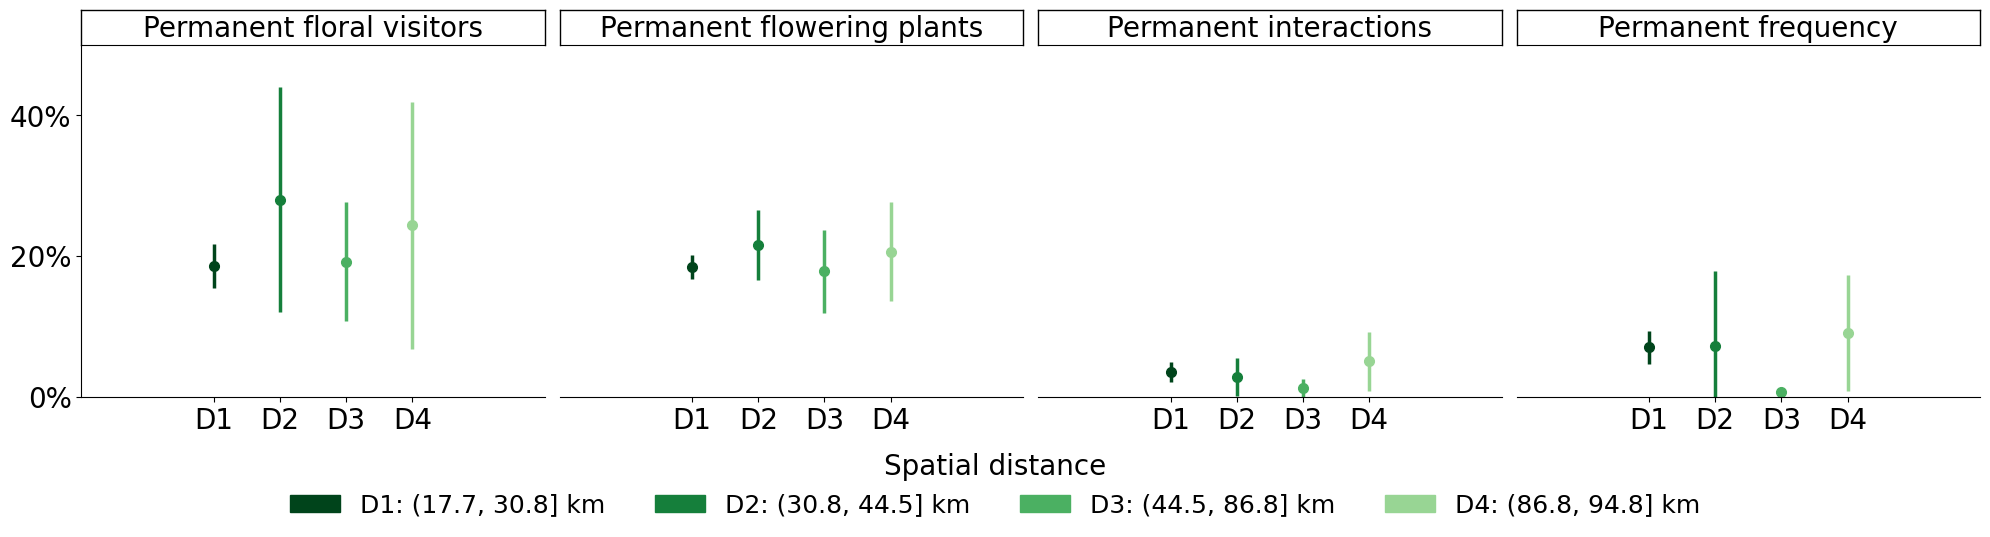

In [17]:
#For the chosen site comapre how thigns decay with geographic distance
fig, axes, summary_df = plot_persistence_by_distance(Nodes_df, Changes_df,elinewidth=2.5, capsize=0,markersize=14)
for ax in axes:
    ax.set_ylim(0, 0.5)
plt.savefig("./FIGURES/Figure_3C.png", dpi=150, bbox_inches='tight')

In [19]:
#for all sites 

metric = ['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N = ["PA", "PP", "A1", "P1", "A2", "P2"]

# all possible pairs of sites, without repetition
site_pairs = list(itertools.combinations(sorted(Sites), 2))
comparison_ids = [f"{a}-{b}" for a, b in site_pairs]

Changes_all_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric],
        names=["comparison", "metric"]
    ),
    columns=["n_interactions", "freq_interactions"]
)

Nodes_all_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric_N],
        names=["comparison", "metric"]
    ),
    columns=["n_nodes"]
)

for site_A, site_B in site_pairs:

    comparison = f"{site_A}-{site_B}"

    changes, nodes = rewiring_freq_py(
        networks[site_A],
        networks[site_B]
    )

    changes = changes.set_index("metric")
    nodes = nodes.set_index("metric")

    for m in changes.index:
        Changes_all_df.loc[(comparison, m), "n_interactions"] = changes.loc[m, "n_interactions"]
        Changes_all_df.loc[(comparison, m), "freq_interactions"] = changes.loc[m, "freq_sum"]

    for m in nodes.index:
        Nodes_all_df.loc[(comparison, m), "n_nodes"] = nodes.loc[m, "n_species"]

In [20]:
 #df_dist['bin'], bin_edges = pd.qcut(df_dist['Distance_km'], q=4, labels=['D1', 'D2', 'D3', 'D4'], retbins=True)
#df_dist['bin'] = pd.qcut(df_dist['Distance_km'], q=4, precision=2)
_, bin_edges = pd.qcut(df_dist['Distance_km'], q=4, retbins=True)
bin_edges = np.round(bin_edges, 2)
bin_edges[0] -= 0.01  # to ensure the minimum value is included in the first bin

df_dist['bin'] = pd.cut(df_dist['Distance_km'], bins=bin_edges, include_lowest=True)
df_dist['comparison'] = df_dist.apply(lambda r: '-'.join(sorted([r['Network_1'], r['Network_2']])), axis=1)
distances_all = df_dist[['comparison', 'Distance_km', 'bin']]

In [21]:
distances_all

,comparison,Distance_km,bin
1,GYL-ROR,3.451314,"(3.439, 16.11]"
2,KAR-STE,4.387153,"(3.439, 16.11]"
3,GYL-KOM,4.591010,"(3.439, 16.11]"
4,SPJ-TOM,5.077535,"(3.439, 16.11]"
5,HAS-KAR,5.183956,"(3.439, 16.11]"
...,...,...,...
149,GYL-TAG,86.777745,"(62.16, 94.78]"
150,ROR-TAG,89.050664,"(62.16, 94.78]"
151,HAM-TAG,91.116054,"(62.16, 94.78]"
152,GLA-TAG,92.886174,"(62.16, 94.78]"


In [22]:
Nodes_all_df = (
    Nodes_all_df
    .reset_index()
    .merge(distances_all, on="comparison", how="left")
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)

Changes_all_df = (
    Changes_all_df
    .reset_index()
    .merge(distances_all, on="comparison", how="left")
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)

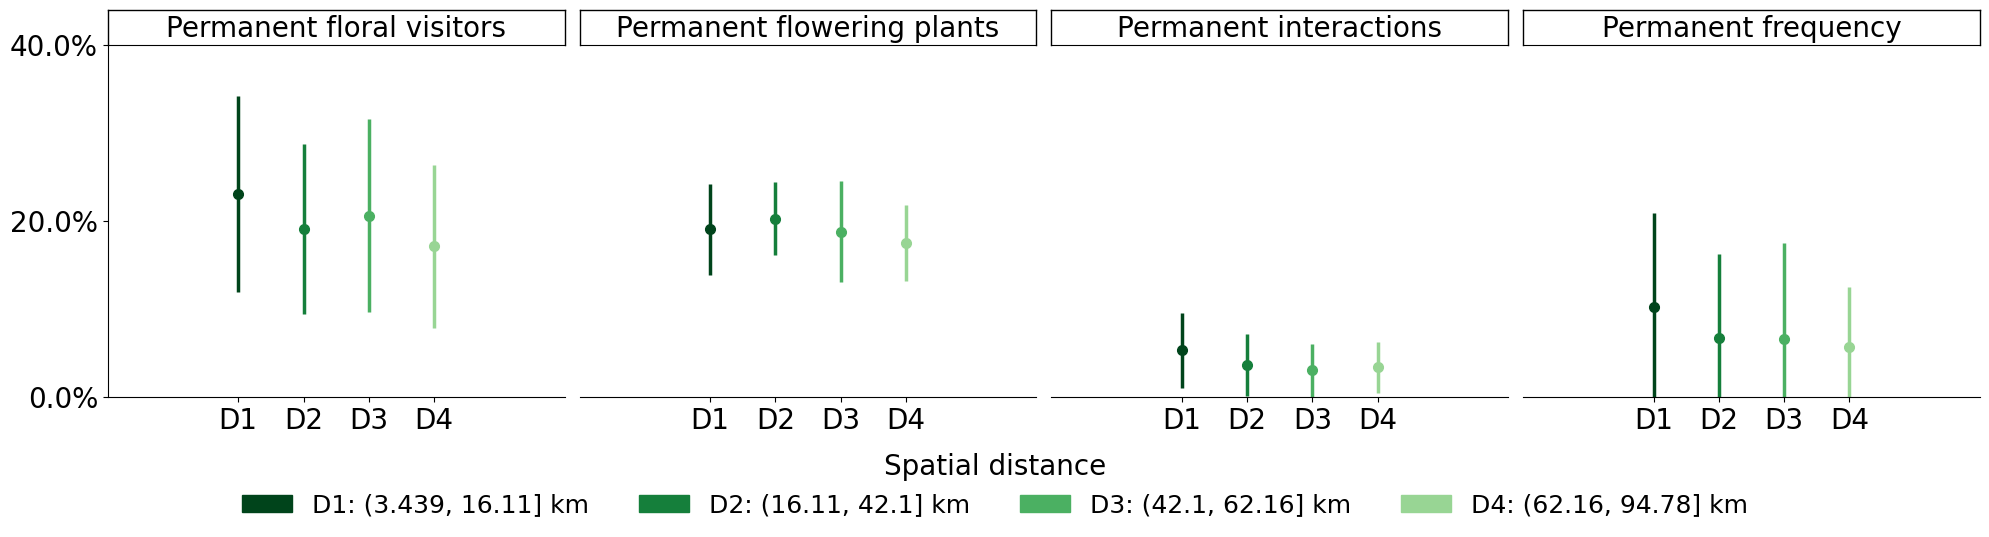

In [23]:
#check how variables decay with space
fig, axes, summary_df = plot_persistence_by_distance(Nodes_all_df, Changes_all_df,elinewidth=2.5, capsize=0,markersize=14)
for ax in axes:
    ax.set_ylim(0, 0.4)
plt.savefig("./FIGURES/Fig_S10.png", dpi=150, bbox_inches='tight')

In [24]:
Nodes_all_df.index.get_level_values('bin').unique()

CategoricalIndex([(16.11, 42.1], (62.16, 94.78], (3.439, 16.11],
                  (42.1, 62.16]],
                 categories=[(3.439, 16.11], (16.11, 42.1], (42.1, 62.16], (62.16, 94.78]], ordered=True, dtype='category', name='bin')

# Relationship with space

In [25]:
#we read landscape categories coverage in each site
df3=pd.read_csv(filename3,sep=';', decimal=',', index_col=0)
df3

,id,sitename,Buffer,arable_crops,leys,PGL,forest,water,urban,fruit
1,HAR,Hardeberga,1250,0.640559,0.025265,0.096971,0.049379,0.007557,0.112801,0.000000
2,TAG,Tågarp,1250,0.673735,0.046857,0.148244,0.035900,0.003773,0.046874,0.000530
3,KAG,Kågeröd,1250,0.026543,0.152069,0.160990,0.446313,0.014235,0.021770,0.000000
4,HAS,Hasslebro,1250,0.061745,0.147072,0.211487,0.485405,0.034970,0.047969,0.000509
5,KAR,Kärrstorp,1250,0.252712,0.370701,0.117443,0.188803,0.005155,0.032797,0.000815
...,...,...,...,...,...,...,...,...,...,...
122,PET,Peterslund,750,0.655877,0.080556,0.169864,0.035397,0.015779,0.034567,0.000000
123,HAM,Hammenhög,750,0.779637,0.026325,0.119178,0.009435,0.000000,0.034751,0.000000
124,DAL,Dalby,750,0.013014,0.126795,0.669620,0.092086,0.003001,0.048129,0.000000
125,ASK,Ask-Sonnarp,750,0.494538,0.226376,0.097890,0.128731,0.000906,0.022784,0.000000


In [26]:
Sites2 = list(df1["Network_id"].unique())
pairs = list(itertools.combinations(sorted(Sites2), 2))  # without repetition, fixed alphabetical order
comparison_ids = [f"{a}-{b}" for a, b in pairs]

mi_changes = pd.MultiIndex.from_product([comparison_ids, metric], names=["comparison", "metric"])
Spatial_Changes_df = pd.DataFrame(index=mi_changes, columns=["n_interactions", "freq_sum"])

mi_nodes = pd.MultiIndex.from_product([comparison_ids, metric_N], names=["comparison", "metric"])
Spatial_Nodes_df = pd.DataFrame(index=mi_nodes, columns=["n_species"])

for (site_A, site_B), comp_id in zip(pairs, comparison_ids):
    result, node_counts = rewiring_freq_py(networks[site_A], networks[site_B])

    for m in metric:
        row = result.loc[result['metric'] == m]
        Spatial_Changes_df.loc[(comp_id, m), 'n_interactions'] = row['n_interactions'].values[0]
        Spatial_Changes_df.loc[(comp_id, m), 'freq_sum'] = row['freq_sum'].values[0]

    for m in metric_N:
        row = node_counts.loc[node_counts['metric'] == m]
        Spatial_Nodes_df.loc[(comp_id, m), 'n_species'] = row['n_species'].values[0]


Spatial_Changes_df.dropna(inplace=True)
Spatial_Nodes_df.dropna(inplace=True)


Spatial_Changes_df['n_interactions'] = pd.to_numeric(Spatial_Changes_df['n_interactions'], errors='coerce')
Spatial_Changes_df['freq_sum'] = pd.to_numeric(Spatial_Changes_df['freq_sum'], errors='coerce')
Spatial_Nodes_df['n_species'] = pd.to_numeric(Spatial_Nodes_df['n_species'], errors='coerce')

In [27]:
Spatial_Nodes_df

n_species
comparison metric           
ASK-DAL    PA             13
           PP              4
           A1             21
           P1              6
           A2             26
...                      ...
TAG-TOM    PP              4
           A1             26
           P1             13
           A2             45
           P2              8

[918 rows x 1 columns]

In [28]:
# create a distance matrix of arable land cover (%) between sites
from scipy.spatial.distance import pdist, squareform
sites_sorted = sorted(Sites)
#1250   1500   1750  2000    250    500    750     
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']
df_1250 = df3[df3['Buffer'] == 2000].set_index('id')[landuse_cols]

arable_dist = pdist(df_1250[['arable_crops']].values, metric='cityblock')
arable_matrix = pd.DataFrame(squareform(arable_dist), index=df_1250.index, columns=df_1250.index)
arable_matrix = arable_matrix.sort_index(axis=0).sort_index(axis=1)
arable_matrix

id,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
id,,,,,,,,,,,,,,,,,,
ASK,0.000000,0.419383,0.066343,0.418575,0.306866,0.206817,0.388806,0.447356,0.189125,0.157062,0.098522,0.164496,0.248741,0.386953,0.097326,0.009787,0.249041,0.152161
DAL,0.419383,0.000000,0.353040,0.000807,0.726249,0.626200,0.030577,0.027973,0.230258,0.262321,0.517905,0.583879,0.668124,0.032429,0.516708,0.429170,0.668423,0.571543
GLA,0.066343,0.353040,0.000000,0.352232,0.373209,0.273160,0.322463,0.381013,0.122782,0.090719,0.164865,0.230839,0.315084,0.320611,0.163669,0.076130,0.315384,0.218504
GYL,0.418575,0.000807,0.352232,0.000000,0.725441,0.625392,0.029770,0.028780,0.229451,0.261514,0.517098,0.583071,0.667317,0.031622,0.515901,0.428363,0.667616,0.570736
HAM,0.306866,0.726249,0.373209,0.725441,0.000000,0.100049,0.695672,0.754222,0.495990,0.463928,0.208343,0.142370,0.058124,0.693819,0.209540,0.297078,0.057825,0.154705
HAR,0.206817,0.626200,0.273160,0.625392,0.100049,0.000000,0.595623,0.654172,0.395941,0.363878,0.108294,0.042321,0.041925,0.593770,0.109491,0.197029,0.042224,0.054656
HAS,0.388806,0.030577,0.322463,0.029770,0.695672,0.595623,0.000000,0.058550,0.199681,0.231744,0.487328,0.553302,0.637547,0.001852,0.486131,0.398593,0.637846,0.540966
KAG,0.447356,0.027973,0.381013,0.028780,0.754222,0.654172,0.058550,0.000000,0.258231,0.290294,0.545878,0.611852,0.696097,0.060402,0.544681,0.457143,0.696396,0.599516
KAR,0.189125,0.230258,0.122782,0.229451,0.495990,0.395941,0.199681,0.258231,0.000000,0.032063,0.287647,0.353621,0.437866,0.197829,0.286450,0.198912,0.438165,0.341285


In [29]:
#crear una matriz de distancias de Bray Curtis del paisaje de cada apr de sitios. We dont use this
from scipy.spatial.distance import pdist, squareform
sites_sorted = sorted(Sites)
#1250   1500   1750  2000    250    500    750     
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']

df_1250 = df3[df3['Buffer'] == 2000].set_index('id')[landuse_cols]

bc_dist = pdist(df_1250.values, metric='braycurtis')
bc_matrix = pd.DataFrame(squareform(bc_dist), index=df_1250.index, columns=df_1250.index)
bc_matrix = bc_matrix.sort_index(axis=0).sort_index(axis=1)

In [30]:
bc_matrix

id,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
id,,,,,,,,,,,,,,,,,,
ASK,0.000000,0.492317,0.165653,0.440575,0.339312,0.291168,0.411164,0.472731,0.196503,0.247022,0.135409,0.172557,0.309502,0.400383,0.192061,0.118577,0.303294,0.210958
DAL,0.492317,0.000000,0.475727,0.317227,0.738679,0.667436,0.366765,0.391176,0.415087,0.437178,0.592520,0.605994,0.685964,0.243427,0.606512,0.606843,0.691326,0.617492
GLA,0.165653,0.475727,0.000000,0.424165,0.403696,0.338984,0.421277,0.486446,0.182585,0.089999,0.197316,0.244777,0.339905,0.355895,0.176880,0.126627,0.343418,0.243448
GYL,0.440575,0.317227,0.424165,0.000000,0.751534,0.681213,0.059483,0.113961,0.362403,0.393983,0.563395,0.604883,0.687194,0.217026,0.556169,0.535326,0.693079,0.592216
HAM,0.339312,0.738679,0.403696,0.751534,0.000000,0.090278,0.721910,0.794311,0.517567,0.490058,0.218498,0.178681,0.066251,0.712143,0.226535,0.344344,0.063230,0.163815
HAR,0.291168,0.667436,0.338984,0.681213,0.090278,0.000000,0.651953,0.722921,0.456107,0.426591,0.160629,0.126277,0.057599,0.653551,0.178823,0.283251,0.058260,0.112602
HAS,0.411164,0.366765,0.421277,0.059483,0.721910,0.651953,0.000000,0.117572,0.330081,0.405567,0.536388,0.577952,0.658067,0.234184,0.520951,0.500789,0.663798,0.564620
KAG,0.472731,0.391176,0.486446,0.113961,0.794311,0.722921,0.117572,0.000000,0.402955,0.475149,0.589139,0.632261,0.728451,0.305775,0.603849,0.577721,0.734767,0.631612
KAR,0.196503,0.415087,0.182585,0.362403,0.517567,0.456107,0.330081,0.402955,0.000000,0.115206,0.319768,0.366793,0.456079,0.290523,0.305344,0.227927,0.457334,0.356081


In [31]:
#create a matrix of distances in km
dist_km_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in df_dist.iterrows():
    a, b, d = row['Network_1'], row['Network_2'], row['Distance_km']
    dist_km_matrix.loc[a, b] = d
    dist_km_matrix.loc[b, a] = d

dist_km_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,33.550866,78.501580,72.261262,78.280643,28.894792,11.182565,6.323301,10.716247,71.744938,30.686002,29.125526,80.985837,74.198453,65.352598,15.097824,17.688855,67.978871
DAL,33.550866,NaN,57.393116,51.954311,52.956315,6.437677,30.790614,39.873651,26.098787,49.572202,17.704603,22.763407,57.999608,54.917584,42.104272,24.015315,40.584471,42.637202
GLA,78.501580,57.393116,NaN,6.276967,11.726101,63.354681,68.579832,83.343663,67.791159,7.893037,48.444499,49.385563,5.278300,5.651265,15.400473,63.405399,92.886174,16.669001
GYL,72.261262,51.954311,6.276967,NaN,13.356087,57.780483,62.306717,77.076381,61.554897,4.591010,42.316776,43.138837,10.134132,3.451314,10.806058,57.168163,86.777745,13.716668
HAM,78.280643,52.956315,11.726101,13.356087,NaN,59.267224,69.305070,83.659741,67.652230,9.680345,47.596683,49.819006,7.752718,15.586866,13.206314,63.356422,91.116054,10.495306
HAR,28.894792,6.437677,63.354681,57.780483,59.267224,NaN,28.039034,35.174979,22.986025,55.585406,20.342469,24.539106,64.148394,60.650861,48.162595,21.917410,34.383911,48.899650
HAS,11.182565,30.790614,68.579832,62.306717,69.305070,28.039034,NaN,14.841323,5.183956,62.161996,22.402612,19.492411,71.397597,64.034104,56.175487,7.087957,28.676763,59.255051
KAG,6.323301,39.873651,83.343663,77.076381,83.659741,35.174979,14.841323,NaN,16.094894,76.802726,36.184160,34.047012,86.047739,78.852223,70.621359,20.313107,17.794594,73.453511
KAR,10.716247,26.098787,67.791159,61.554897,67.652230,22.986025,5.183956,16.094894,NaN,61.032239,20.104128,18.431235,70.274353,63.520913,54.678726,4.387153,26.722400,57.398848
KOM,71.744938,49.572202,7.893037,4.591010,9.680345,55.585406,62.161996,76.802726,61.032239,NaN,41.349413,42.755718,9.246033,7.859252,7.511558,56.663272,85.658274,9.363189


In [32]:
# To run the Mantel test, each variable of interest must be converted into a matrix.
# Thus, we convert Spatial_changes_df into matrices of the variables we are interested in
# matrix of % permanent polliantor species
Spatial_Nodes_wide = Spatial_Nodes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_species'
)
Spatial_Nodes_wide.columns.name = None
Spatial_Nodes_wide.reset_index(inplace=True)

Spatial_Nodes_wide[['site_A', 'site_B']] = Spatial_Nodes_wide['comparison'].str.split('-', n=1, expand=True)

Spatial_Nodes_wide['poll_permanent_ratio'] = (
    Spatial_Nodes_wide['PA'] / (Spatial_Nodes_wide['PA'] + Spatial_Nodes_wide['A1'] + Spatial_Nodes_wide['A2'])
)

poll_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Nodes_wide.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['poll_permanent_ratio']
    poll_matrix.loc[a, b] = v
    poll_matrix.loc[b, a] = v

poll_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.216667,0.206897,0.196078,0.202899,0.163636,0.250000,0.238095,0.290323,0.206897,0.196078,0.237288,0.164384,0.079365,0.186667,0.267857,0.161765,0.180723
DAL,0.216667,NaN,0.229508,0.222222,0.189189,0.210526,0.209677,0.169014,0.250000,0.315789,0.269231,0.278689,0.184211,0.158730,0.205128,0.151515,0.253731,0.256098
GLA,0.206897,0.229508,NaN,0.125000,0.197183,0.200000,0.161290,0.194030,0.205882,0.241379,0.260000,0.190476,0.160000,0.147541,0.151899,0.216667,0.173913,0.204819
GYL,0.196078,0.222222,0.125000,NaN,0.085714,0.187500,0.105263,0.126984,0.140625,0.235294,0.173913,0.222222,0.147059,0.129630,0.188406,0.142857,0.090909,0.137500
HAM,0.202899,0.189189,0.197183,0.085714,NaN,0.179104,0.164384,0.148148,0.172840,0.231884,0.117647,0.275362,0.219512,0.106667,0.195402,0.194444,0.305556,0.228261
HAR,0.163636,0.210526,0.200000,0.187500,0.179104,NaN,0.178571,0.174603,0.206349,0.245283,0.187500,0.301887,0.173913,0.142857,0.214286,0.155172,0.229508,0.175000
HAS,0.250000,0.209677,0.161290,0.105263,0.164384,0.178571,NaN,0.212121,0.281250,0.161290,0.188679,0.190476,0.101266,0.129032,0.109756,0.158730,0.173913,0.176471
KAG,0.238095,0.169014,0.194030,0.126984,0.148148,0.174603,0.212121,NaN,0.200000,0.176471,0.145161,0.220588,0.187500,0.098592,0.151163,0.265625,0.202703,0.200000
KAR,0.290323,0.250000,0.205882,0.140625,0.172840,0.206349,0.281250,0.200000,NaN,0.171429,0.216667,0.250000,0.168675,0.212121,0.216867,0.169014,0.197368,0.250000
KOM,0.206897,0.315789,0.241379,0.235294,0.231884,0.245283,0.161290,0.176471,0.171429,NaN,0.211538,0.229508,0.208333,0.147541,0.229730,0.216667,0.191176,0.234568


In [33]:
# matrix of % permanent plant species
Spatial_Nodes_wide['plant_permanent_ratio'] = (
    Spatial_Nodes_wide['PP'] / (Spatial_Nodes_wide['PP'] + Spatial_Nodes_wide['P1'] + Spatial_Nodes_wide['P2'])
)

plant_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Nodes_wide.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['plant_permanent_ratio']
    plant_matrix.loc[a, b] = v
    plant_matrix.loc[b, a] = v

plant_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.222222,0.187500,0.222222,0.157895,0.117647,0.416667,0.461538,0.333333,0.222222,0.368421,0.190476,0.173913,0.052632,0.187500,0.416667,0.173913,0.294118
DAL,0.222222,NaN,0.166667,0.333333,0.142857,0.166667,0.117647,0.235294,0.222222,0.411765,0.166667,0.173913,0.160000,0.100000,0.235294,0.266667,0.160000,0.411765
GLA,0.187500,0.166667,NaN,0.235294,0.235294,0.200000,0.230769,0.125000,0.266667,0.235294,0.315789,0.263158,0.181818,0.055556,0.125000,0.230769,0.444444,0.166667
GYL,0.222222,0.333333,0.235294,NaN,0.142857,0.105263,0.055556,0.166667,0.157895,0.333333,0.217391,0.350000,0.115385,0.047619,0.312500,0.187500,0.318182,0.200000
HAM,0.157895,0.142857,0.235294,0.142857,NaN,0.166667,0.117647,0.050000,0.157895,0.142857,0.120000,0.173913,0.115385,0.047619,0.166667,0.117647,0.318182,0.263158
HAR,0.117647,0.166667,0.200000,0.105263,0.166667,NaN,0.066667,0.125000,0.266667,0.312500,0.086957,0.090909,0.238095,0.266667,0.058824,0.142857,0.130435,0.235294
HAS,0.416667,0.117647,0.230769,0.055556,0.117647,0.066667,NaN,0.333333,0.307692,0.117647,0.277778,0.100000,0.090909,0.000000,0.142857,0.272727,0.142857,0.187500
KAG,0.461538,0.235294,0.125000,0.166667,0.050000,0.125000,0.333333,NaN,0.187500,0.235294,0.250000,0.142857,0.181818,0.055556,0.285714,0.600000,0.181818,0.235294
KAR,0.333333,0.222222,0.266667,0.157895,0.157895,0.266667,0.307692,0.187500,NaN,0.157895,0.300000,0.190476,0.080000,0.052632,0.055556,0.307692,0.227273,0.294118
KOM,0.222222,0.411765,0.235294,0.333333,0.142857,0.312500,0.117647,0.235294,0.157895,NaN,0.166667,0.227273,0.318182,0.157895,0.312500,0.187500,0.160000,0.411765


In [34]:
# % permanent interactions
Spatial_Changes_n = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_interactions'
)
Spatial_Changes_n.columns.name = None
Spatial_Changes_n.reset_index(inplace=True)

Spatial_Changes_n[['site_A', 'site_B']] = Spatial_Changes_n['comparison'].str.split('-', n=1, expand=True)

permanent_cats = ['CN_CI', 'CN_DI', 'CN_II']
all_cats = ['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']

Spatial_Changes_n['permanent_interactions_ratio'] = (
    Spatial_Changes_n[permanent_cats].sum(axis=1) / Spatial_Changes_n[all_cats].sum(axis=1)
)

interactions_n_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_n.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['permanent_interactions_ratio']
    interactions_n_matrix.loc[a, b] = v
    interactions_n_matrix.loc[b, a] = v

interactions_n_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.031250,0.011111,0.054795,0.065041,0.036585,0.088608,0.159091,0.120370,0.063158,0.025000,0.044248,0.034783,0.000000,0.025641,0.126437,0.016529,0.084615
DAL,0.031250,NaN,0.000000,0.023810,0.029412,0.010753,0.043956,0.057143,0.065574,0.134021,0.045977,0.016000,0.032258,0.010204,0.040323,0.019048,0.031250,0.079137
GLA,0.011111,0.000000,NaN,0.000000,0.081967,0.036145,0.023529,0.019802,0.025210,0.020000,0.050633,0.053097,0.052632,0.022472,0.016807,0.020619,0.059829,0.021583
GYL,0.054795,0.023810,0.000000,NaN,0.000000,0.000000,0.000000,0.059524,0.009346,0.060241,0.000000,0.009615,0.009524,0.000000,0.049020,0.036585,0.000000,0.024000
HAM,0.065041,0.029412,0.081967,0.000000,NaN,0.032787,0.032520,0.051471,0.051948,0.044118,0.016529,0.067114,0.073826,0.007692,0.052288,0.085938,0.100671,0.089820
HAR,0.036585,0.010753,0.036145,0.000000,0.032787,NaN,0.000000,0.010417,0.054545,0.032258,0.000000,0.018018,0.045872,0.000000,0.000000,0.021978,0.000000,0.038168
HAS,0.088608,0.043956,0.023529,0.000000,0.032520,0.000000,NaN,0.065217,0.114286,0.000000,0.054054,0.008850,0.000000,0.000000,0.000000,0.032967,0.043860,0.053846
KAG,0.159091,0.057143,0.019802,0.059524,0.051471,0.010417,0.065217,NaN,0.099174,0.056075,0.056180,0.040000,0.023438,0.000000,0.031250,0.208791,0.046512,0.100719
KAR,0.120370,0.065574,0.025210,0.009346,0.051948,0.054545,0.114286,0.099174,NaN,0.023256,0.086538,0.049296,0.027397,0.000000,0.006667,0.084034,0.047619,0.088608
KOM,0.063158,0.134021,0.020000,0.060241,0.044118,0.032258,0.000000,0.056075,0.023256,NaN,0.000000,0.023810,0.015625,0.020202,0.073770,0.038095,0.007519,0.142857


In [35]:
# frequency of itneraactions permanent
Spatial_Changes_freq = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='freq_sum'
)
Spatial_Changes_freq.columns.name = None
Spatial_Changes_freq.reset_index(inplace=True)

Spatial_Changes_freq[['site_A', 'site_B']] = Spatial_Changes_freq['comparison'].str.split('-', n=1, expand=True)

Spatial_Changes_freq['permanent_frequency_ratio'] = (
    Spatial_Changes_freq[permanent_cats].sum(axis=1) / Spatial_Changes_freq[all_cats].sum(axis=1)
)

interactions_freq_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_freq.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['permanent_frequency_ratio']
    interactions_freq_matrix.loc[a, b] = v
    interactions_freq_matrix.loc[b, a] = v

interactions_freq_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.014337,0.005747,0.027211,0.075758,0.015464,0.178571,0.259067,0.276596,0.043243,0.051613,0.026820,0.018868,0.000000,0.011407,0.309160,0.045685,0.182336
DAL,0.014337,NaN,0.000000,0.008000,0.029018,0.003300,0.028000,0.126100,0.048023,0.540000,0.023438,0.010667,0.015823,0.045283,0.019553,0.154412,0.016340,0.333333
GLA,0.005747,0.000000,NaN,0.000000,0.176471,0.078947,0.027211,0.021277,0.056000,0.021277,0.041379,0.064000,0.118812,0.012579,0.011673,0.009967,0.076087,0.013263
GYL,0.027211,0.008000,0.000000,NaN,0.000000,0.000000,0.000000,0.028169,0.004184,0.031847,0.000000,0.004065,0.005236,0.000000,0.035556,0.025547,0.000000,0.057803
HAM,0.075758,0.029018,0.176471,0.000000,NaN,0.077348,0.031546,0.157068,0.052885,0.033708,0.018868,0.050725,0.168605,0.002985,0.076010,0.215909,0.200581,0.116232
HAR,0.015464,0.003300,0.078947,0.000000,0.077348,NaN,0.000000,0.041199,0.073529,0.080189,0.000000,0.054608,0.057522,0.000000,0.000000,0.177914,0.000000,0.085427
HAS,0.178571,0.028000,0.027211,0.000000,0.031546,0.000000,NaN,0.109524,0.281690,0.000000,0.057851,0.028112,0.000000,0.000000,0.000000,0.039427,0.052023,0.037464
KAG,0.259067,0.126100,0.021277,0.028169,0.157068,0.041199,0.109524,NaN,0.247232,0.133858,0.182243,0.184127,0.132616,0.000000,0.018349,0.543071,0.066929,0.184066
KAR,0.276596,0.048023,0.056000,0.004184,0.052885,0.073529,0.281690,0.247232,NaN,0.050360,0.076923,0.067647,0.033670,0.000000,0.002833,0.266854,0.104693,0.161593
KOM,0.043243,0.540000,0.021277,0.031847,0.033708,0.080189,0.000000,0.133858,0.050360,NaN,0.000000,0.024476,0.012931,0.034286,0.083650,0.234177,0.004484,0.368116


In [36]:
# %rewiring
rewiring_cats = ['CN_LI', 'CN_GI']
turnover_cats = ['L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
all_change_cats = rewiring_cats + turnover_cats

Spatial_Changes_n['rewiring_ratio'] = (
    Spatial_Changes_n[rewiring_cats].sum(axis=1) / Spatial_Changes_n[all_change_cats].sum(axis=1)
)

rewiring_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_n.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['rewiring_ratio']
    rewiring_matrix.loc[a, b] = v
    rewiring_matrix.loc[b, a] = v

rewiring_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.172043,0.089888,0.115942,0.034783,0.050633,0.194444,0.229730,0.157895,0.101124,0.205128,0.083333,0.099099,0.011111,0.070175,0.236842,0.075630,0.117647
DAL,0.172043,NaN,0.070000,0.219512,0.075758,0.054348,0.080460,0.131313,0.184211,0.226190,0.120482,0.073171,0.058333,0.082474,0.092437,0.174757,0.096774,0.265625
GLA,0.089888,0.070000,NaN,0.012821,0.187500,0.050000,0.108434,0.121212,0.181034,0.091837,0.186667,0.149533,0.092593,0.011494,0.059829,0.200000,0.136364,0.110294
GYL,0.115942,0.219512,0.012821,NaN,0.050847,0.041667,0.000000,0.113924,0.066038,0.166667,0.101449,0.145631,0.057692,0.025974,0.134021,0.126582,0.045455,0.114754
HAM,0.034783,0.075758,0.187500,0.050847,NaN,0.101695,0.067227,0.023256,0.041096,0.100000,0.075630,0.194245,0.123188,0.023256,0.103448,0.034188,0.291045,0.105263
HAR,0.050633,0.054348,0.050000,0.041667,0.101695,NaN,0.024691,0.126316,0.125000,0.111111,0.064935,0.073394,0.105769,0.152941,0.026087,0.112360,0.067797,0.126984
HAS,0.194444,0.080460,0.108434,0.000000,0.067227,0.024691,NaN,0.104651,0.161290,0.020619,0.185714,0.089286,0.026087,0.000000,0.008621,0.113636,0.082569,0.081301
KAG,0.229730,0.131313,0.121212,0.113924,0.023256,0.126316,0.104651,NaN,0.100917,0.099010,0.107143,0.158333,0.144000,0.000000,0.145161,0.208333,0.130081,0.104000
KAR,0.157895,0.184211,0.181034,0.066038,0.041096,0.125000,0.161290,0.100917,NaN,0.111111,0.168421,0.170370,0.084507,0.024793,0.060403,0.128440,0.128571,0.166667
KOM,0.101124,0.226190,0.091837,0.166667,0.100000,0.111111,0.020619,0.099010,0.111111,NaN,0.086022,0.073171,0.158730,0.072165,0.141593,0.128713,0.053030,0.280702


# Mantel tests


In [37]:
#lets perform the mantel tests
network_matrices = {
    'Poll. permanent ratio':        poll_matrix,
    'Plant permanent ratio':        plant_matrix,
    'Permanent interactions (n)':   interactions_n_matrix,
    'Permanent interactions (freq)':interactions_freq_matrix,
    'Rewiring ratio':               rewiring_matrix,
}

distance_matrices = {
    'distance_km':   dist_km_matrix,
    'landscape_arable':  arable_matrix,
}

results = []
for var_label, var_matrix in network_matrices.items():
    for dist_label, dist_matrix in distance_matrices.items():
        rho, p = mantel_test(var_matrix, dist_matrix, n_perm=999)
        results.append({'variable': var_label, 'distance_type': dist_label,
                         'mantel_rho': rho, 'p_value': p})


mantel_df = pd.DataFrame(results)

from statsmodels.stats.multitest import multipletests

mantel_df['p_fdr'] = multipletests(mantel_df['p_value'], method='fdr_bh')[1]
mantel_df

,variable,distance_type,mantel_rho,p_value,p_fdr
0,Poll. permanent ratio,distance_km,-0.167703,0.032,0.075000
1,Poll. permanent ratio,landscape_arable,-0.158313,0.045,0.075000
2,Plant permanent ratio,distance_km,-0.192789,0.021,0.075000
3,Plant permanent ratio,landscape_arable,-0.057510,0.470,0.470000
4,Permanent interactions (n),distance_km,-0.172390,0.040,0.075000
5,Permanent interactions (n),landscape_arable,-0.103429,0.228,0.253333
6,Permanent interactions (freq),distance_km,-0.168417,0.038,0.075000
7,Permanent interactions (freq),landscape_arable,-0.127475,0.112,0.140000
8,Rewiring ratio,distance_km,-0.200562,0.013,0.075000
9,Rewiring ratio,landscape_arable,-0.142144,0.061,0.087143


In [40]:
# --- build the Mantel test results table for LaTeX ---

# 1. format each cell as "rho (p)" with 2 decimals
mantel_df['cell'] = mantel_df.apply(
    lambda r: f"{r['mantel_rho']:.2f} ({r['p_fdr']:.2f})", axis=1
)

# 2. pivot: variables as rows, distance_type as columns
table = mantel_df.pivot(index='variable', columns='distance_type', values='cell')

# 3. rename rows and columns for the manuscript
row_labels = {
    'Poll. permanent ratio': 'Pollinators (\\% permanent)',
    'Plant permanent ratio': 'Plants (\\% permanent)',
    'Permanent interactions (n)': 'Interactions (\\% permanent, count)',
    'Permanent interactions (freq)': 'Interactions (\\% permanent, frequency)',
    'Rewiring ratio': 'Rewiring (\\%)',
}
col_labels = {
    'distance_km': 'Geographic distance',
    'landscape_arable': 'Landscape',
}

table = table.rename(index=row_labels, columns=col_labels)
table = table.loc[list(row_labels.values()), list(col_labels.values())]  # orden fijo

# 4. export to LaTeX
latex_table = table.to_latex(
    index=True,
    escape=False,          # para que el \% no se escape doble
    column_format="lcc",
    caption="Mantel correlation coefficients (Spearman's $\\rho$) and permutation-based $p$-values (in parentheses) between each network persistence metric and geographic distance or landscape dissimilarity (absolute difference in \\% arable crops).",
    label="tab:mantel_results",
)

filename="./FIGURES/Table_S12.tex"
with open(filename, "w") as f:
    f.write(latex_table)
print(latex_table)

\begin{table}
\caption{Mantel correlation coefficients (Spearman's $\rho$) and permutation-based $p$-values (in parentheses) between each network persistence metric and geographic distance or landscape dissimilarity (absolute difference in \% arable crops).}
\label{tab:mantel_results}
\begin{tabular}{lcc}
\toprule
distance_type & Geographic distance & Landscape \\
variable &  &  \\
\midrule
Pollinators (\% permanent) & -0.17 (0.07) & -0.16 (0.07) \\
Plants (\% permanent) & -0.19 (0.07) & -0.06 (0.47) \\
Interactions (\% permanent, count) & -0.17 (0.07) & -0.10 (0.25) \\
Interactions (\% permanent, frequency) & -0.17 (0.07) & -0.13 (0.14) \\
Rewiring (\%) & -0.20 (0.07) & -0.14 (0.09) \\
\bottomrule
\end{tabular}
\end{table}



In [66]:

mantel_df

,variable,distance_type,mantel_rho,p_value,p_fdr,cell
0,Poll. permanent ratio,distance_km,-0.167703,0.032,0.075000,-0.17 (0.07)
1,Poll. permanent ratio,landscape_arable,-0.158313,0.045,0.075000,-0.16 (0.07)
2,Plant permanent ratio,distance_km,-0.192789,0.021,0.075000,-0.19 (0.07)
3,Plant permanent ratio,landscape_arable,-0.057510,0.470,0.470000,-0.06 (0.47)
4,Permanent interactions (n),distance_km,-0.172390,0.040,0.075000,-0.17 (0.07)
5,Permanent interactions (n),landscape_arable,-0.103429,0.228,0.253333,-0.10 (0.25)
6,Permanent interactions (freq),distance_km,-0.168417,0.038,0.075000,-0.17 (0.07)
7,Permanent interactions (freq),landscape_arable,-0.127475,0.112,0.140000,-0.13 (0.14)
8,Rewiring ratio,distance_km,-0.200562,0.013,0.075000,-0.20 (0.07)
9,Rewiring ratio,landscape_arable,-0.142144,0.061,0.087143,-0.14 (0.09)


In [69]:
results_tag

,distance,metric,n,rho,p_value,significant
0,Distance_km,Poll_perm,17,-0.017167,0.947859,False
1,Distance_km,Plant_perm,17,0.083641,0.749610,False
2,Distance_km,Int_perm_count,17,-0.022113,0.932866,False
3,Distance_km,Int_perm_freq,17,-0.095823,0.714485,False
4,Distance_km,Rewiring_pct,17,0.019608,0.940458,False
5,landscape_arable,Poll_perm,17,-0.362968,0.152160,False
6,landscape_arable,Plant_perm,17,-0.102092,0.696615,False
7,landscape_arable,Int_perm_count,17,-0.098280,0.707463,False
8,landscape_arable,Int_perm_freq,17,-0.260443,0.312685,False
9,landscape_arable,Rewiring_pct,17,-0.321078,0.208898,False


In [78]:
latex_table2 = make_latex_table(results_tag)
print(latex_table2)

\begin{table}[h]
\centering
\begin{tabular}{lcc}
\hline
Metric & Geographic distance & Landscape \\
\hline
Pollinators (\% permanent) & -0.02 (0.95) & -0.36 (0.15) \\
Plants (\% permanent) & 0.08 (0.75) & -0.10 (0.70) \\
Interactions (\% permanent, count) & -0.02 (0.93) & -0.10 (0.71) \\
Interactions (\% permanent, frequency) & -0.10 (0.71) & -0.26 (0.31) \\
Rewiring (\%) & 0.02 (0.94) & -0.32 (0.21) \\
\hline
\end{tabular}
\caption{Spearman correlations ($\rho$, with $p$-values in parentheses) between each network permanence metric and geographic distance or landscape dissimilarity, for site TAG compared against all other sites.}
\label{tab_TAG_correlations}
\end{table}
